In [ ]:
!unzip -q "/content/archive(1).zip" -d /content/data
!ls /content/data

unzip:  cannot find or open /content/archive(1).zip, /content/archive(1).zip.zip or /content/archive(1).zip.ZIP.
ls: cannot access '/content/data': No such file or directory


In [ ]:
!unzip -q "/archive(1).zip" -d /content/data
!ls /content/data

olist_customers_dataset.csv	  olist_orders_dataset.csv
olist_geolocation_dataset.csv	  olist_products_dataset.csv
olist_order_items_dataset.csv	  olist_sellers_dataset.csv
olist_order_payments_dataset.csv  product_category_name_translation.csv
olist_order_reviews_dataset.csv


In [ ]:
import pandas as pd

orders = pd.read_csv("/content/data/olist_orders_dataset.csv")
print(orders.shape)
print(orders.isnull().sum())
print(orders['order_status'].value_counts())

(99441, 8)
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [ ]:
items = pd.read_csv("/content/data/olist_order_items_dataset.csv")
customers = pd.read_csv("/content/data/olist_customers_dataset.csv")
payments = pd.read_csv("/content/data/olist_order_payments_dataset.csv")
reviews = pd.read_csv("/content/data/olist_order_reviews_dataset.csv")
products = pd.read_csv("/content/data/olist_products_dataset.csv")

orders = orders[orders['order_status'] == 'delivered'].copy()
date_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

print(orders.shape)
print(items.shape, customers.shape, payments.shape, reviews.shape, products.shape)

(96478, 8)
(112650, 7) (99441, 5) (103886, 5) (99224, 7) (32951, 9)


In [ ]:
df = orders.merge(items, on='order_id').merge(customers, on='customer_id')
df['month'] = df['order_purchase_timestamp'].dt.to_period('M')
df['revenue'] = df['price']

monthly = df.groupby('month').agg(
    revenue=('revenue', 'sum'),
    orders=('order_id', 'nunique')
)
monthly['aov'] = monthly['revenue'] / monthly['orders']
monthly['growth_%'] = monthly['revenue'].pct_change() * 100

print(monthly.round(1))
print("Total revenue:", round(df['revenue'].sum()))

          revenue  orders    aov   growth_%
month                                      
2016-09     135.0       1  135.0        NaN
2016-10   40325.1     265  152.2    29777.1
2016-12      10.9       1   10.9     -100.0
2017-01  111798.4     750  149.1  1025573.0
2017-02  234223.4    1653  141.7      109.5
2017-03  359198.8    2546  141.1       53.4
2017-04  340669.7    2303  147.9       -5.2
2017-05  489338.2    3546  138.0       43.6
2017-06  421923.4    3135  134.6      -13.8
2017-07  481604.5    3872  124.4       14.1
2017-08  554699.7    4193  132.3       15.2
2017-09  607399.7    4150  146.4        9.5
2017-10  648247.6    4478  144.8        6.7
2017-11  987765.4    7289  135.5       52.4
2017-12  726033.2    5513  131.7      -26.5
2018-01  924645.0    7069  130.8       27.4
2018-02  826437.1    6555  126.1      -10.6
2018-03  953356.2    7003  136.1       15.4
2018-04  973534.1    6798  143.2        2.1
2018-05  977544.7    6749  144.8        0.4
2018-06  856077.9    6099  140.4

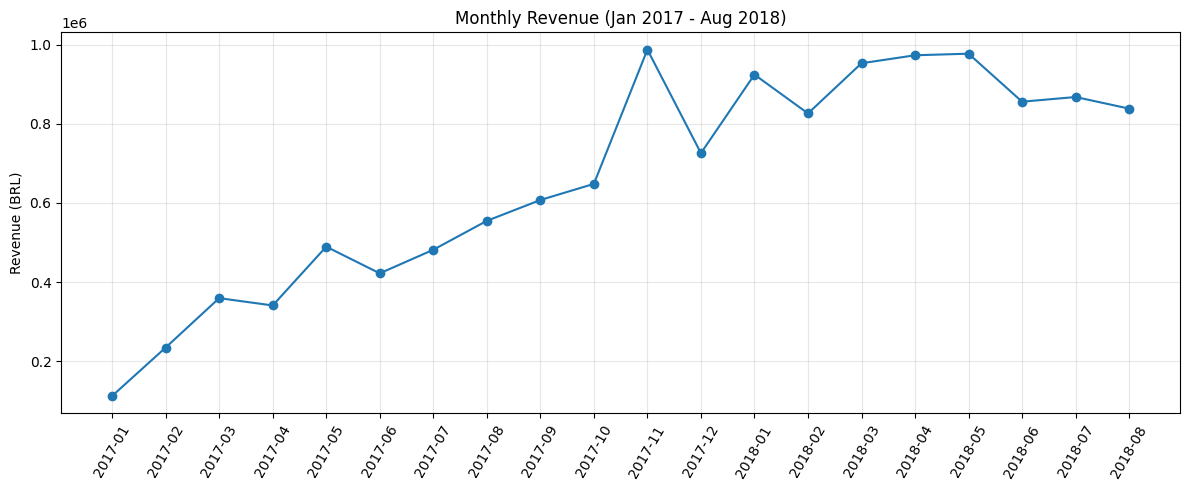

In [ ]:
import matplotlib.pyplot as plt

m = monthly.loc['2017-01':'2018-08'].copy()
m.index = m.index.astype(str)

plt.figure(figsize=(12,5))
plt.plot(m.index, m['revenue'], marker='o')
plt.xticks(rotation=60)
plt.title('Monthly Revenue (Jan 2017 - Aug 2018)')
plt.ylabel('Revenue (BRL)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
translation = pd.read_csv("/content/data/product_category_name_translation.csv")
d = df.merge(products[['product_id','product_category_name']], on='product_id', how='left')
d = d.merge(translation, on='product_category_name', how='left')

cat = d.groupby('product_category_name_english').agg(
    revenue=('price','sum'),
    orders=('order_id','nunique')
).sort_values('revenue', ascending=False)

cat['share_%'] = cat['revenue'] / cat['revenue'].sum() * 100
cat['cum_share_%'] = cat['share_%'].cumsum()

print(cat.head(10).round(1))

                                 revenue  orders  share_%  cum_share_%
product_category_name_english                                         
health_beauty                  1233131.7    8647      9.5          9.5
watches_gifts                  1166177.0    5495      8.9         18.4
bed_bath_table                 1023434.8    9272      7.8         26.2
sports_leisure                  954852.6    7530      7.3         33.6
computers_accessories           888724.6    6530      6.8         40.4
furniture_decor                 711927.7    6307      5.5         45.8
housewares                      615628.7    5743      4.7         50.5
cool_stuff                      610204.1    3559      4.7         55.2
auto                            578966.6    3810      4.4         59.7
toys                            471286.5    3804      3.6         63.3


In [ ]:
rev = reviews.groupby('order_id')['review_score'].mean().reset_index()
dl = orders.merge(rev, on='order_id')
dl['delay_days'] = (dl['order_delivered_customer_date'] - dl['order_estimated_delivery_date']).dt.days
dl['late'] = dl['delay_days'] > 0

print(dl.groupby('late')['review_score'].agg(['mean','count']).round(2))
print("Late %:", round(dl['late'].mean()*100, 1))

       mean  count
late              
False  4.29  89451
True   2.27   6381
Late %: 6.7


In [ ]:
snap = df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = df.groupby('customer_unique_id').agg(
    recency=('order_purchase_timestamp', lambda x: (snap - x.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('price', 'sum')
)

rfm['R'] = pd.qcut(rfm['recency'], 4, labels=[4,3,2,1])
rfm['M'] = pd.qcut(rfm['monetary'], 4, labels=[1,2,3,4])
rfm['F'] = rfm['frequency'].apply(lambda x: 1 if x == 1 else (2 if x == 2 else 3))

rfm['score'] = rfm['R'].astype(int) + rfm['M'].astype(int) + rfm['F']
rfm['segment'] = pd.cut(rfm['score'], [0,4,6,8,11], labels=['Low','Mid','High','Champions'])

print("Total customers:", len(rfm))
print("Repeat customers %:", round((rfm['frequency']>1).mean()*100, 1))
seg = rfm.groupby('segment', observed=True).agg(customers=('monetary','count'), revenue=('monetary','sum'))
seg['rev_share_%'] = seg['revenue'] / seg['revenue'].sum() * 100
print(seg.round(1))

Total customers: 93358
Repeat customers %: 3.0
           customers    revenue  rev_share_%
segment                                     
Low            17376   712273.6          5.4
Mid            40166  4398779.0         33.3
High           29242  5764227.9         43.6
Champions       6574  2346217.6         17.7


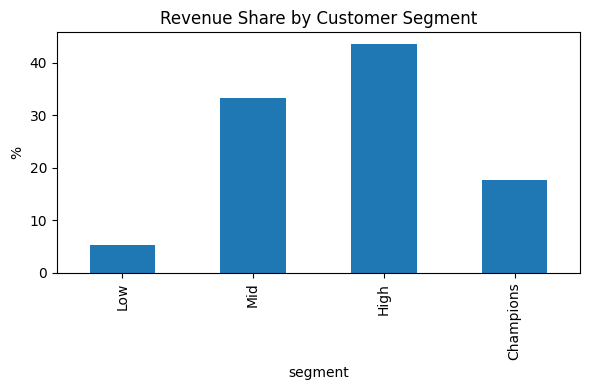

In [ ]:
plt.figure(figsize=(6,4))
seg['rev_share_%'].plot(kind='bar')
plt.title('Revenue Share by Customer Segment')
plt.ylabel('%')
plt.tight_layout()
plt.savefig('rfm_segments.png', dpi=150)
plt.show()

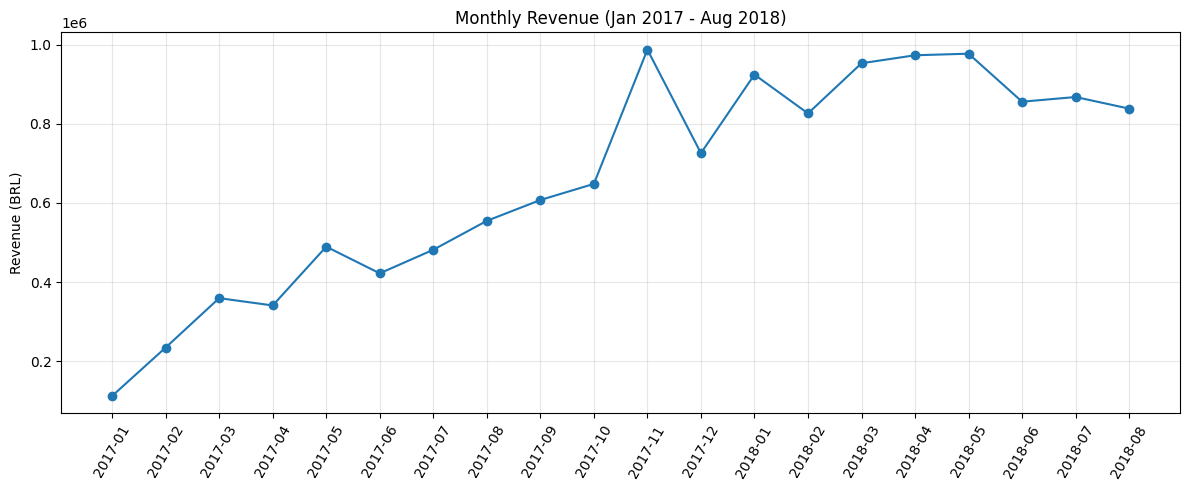

In [ ]:
m = monthly.loc['2017-01':'2018-08'].copy()
m.index = m.index.astype(str)
plt.figure(figsize=(12,5))
plt.plot(m.index, m['revenue'], marker='o')
plt.xticks(rotation=60)
plt.title('Monthly Revenue (Jan 2017 - Aug 2018)')
plt.ylabel('Revenue (BRL)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('monthly_revenue.png', dpi=150)
plt.show()

In [ ]:
import sqlite3
con = sqlite3.connect('olist.db')

o = orders.copy()
for c in date_cols:
    o[c] = o[c].astype(str)
o.to_sql('orders', con, if_exists='replace', index=False)
items.to_sql('items', con, if_exists='replace', index=False)
customers.to_sql('customers', con, if_exists='replace', index=False)

q = """
WITH monthly AS (
  SELECT substr(o.order_purchase_timestamp,1,7) AS month,
         SUM(i.price) AS revenue,
         COUNT(DISTINCT o.order_id) AS orders
  FROM orders o JOIN items i ON o.order_id = i.order_id
  GROUP BY 1
)
SELECT month, ROUND(revenue) AS revenue, orders,
       ROUND(revenue*1.0/orders, 1) AS aov,
       ROUND((revenue - LAG(revenue) OVER (ORDER BY month))*100.0
             / LAG(revenue) OVER (ORDER BY month), 1) AS growth_pct
FROM monthly
WHERE month >= '2017-01'
ORDER BY month
"""
print(pd.read_sql(q, con))

      month   revenue  orders    aov  growth_pct
0   2017-01  111798.0     750  149.1         NaN
1   2017-02  234223.0    1653  141.7       109.5
2   2017-03  359199.0    2546  141.1        53.4
3   2017-04  340670.0    2303  147.9        -5.2
4   2017-05  489338.0    3546  138.0        43.6
5   2017-06  421923.0    3135  134.6       -13.8
6   2017-07  481605.0    3872  124.4        14.1
7   2017-08  554700.0    4193  132.3        15.2
8   2017-09  607400.0    4150  146.4         9.5
9   2017-10  648248.0    4478  144.8         6.7
10  2017-11  987765.0    7289  135.5        52.4
11  2017-12  726033.0    5513  131.7       -26.5
12  2018-01  924645.0    7069  130.8        27.4
13  2018-02  826437.0    6555  126.1       -10.6
14  2018-03  953356.0    7003  136.1        15.4
15  2018-04  973534.0    6798  143.2         2.1
16  2018-05  977545.0    6749  144.8         0.4
17  2018-06  856078.0    6099  140.4       -12.4
18  2018-07  867953.0    6159  140.9         1.4
19  2018-08  838577.